# **TP2 : Modèles Génératifs avec PyTorch sur MNIST**
### **Deuxième Partie : Variational Autoencoder (VAE)**

---
### **Objectifs de cette deuxième partie :**
1. **Principe du VAE :** Passage d'un espace latent déterministe à une distribution conditionnelle $q(z|x) = \mathcal{N}(\mu, \sigma^2)$.
2. **Reparameterization Trick :** Rendre l'échantillonnage différentiable grâce à $z = \mu + \sigma \odot \epsilon$.
3. **Fonction de Perte (ELBO) :** Combinaison de la perte de reconstruction (BCE) et de la divergence de Kullback-Leibler ($D_{KL}$).
4. **Entraînement & Reconstructions :** Entraînement complet et comparaison d'images originales vs reconstruites.
5. **Exploration & Génération :**
   - Visualisation de l'espace latent régularisé 2D.
   - Génération directe de nouveaux chiffres via $z \sim \mathcal{N}(0, I)$.
   - Exploration continue de l'espace latent (grille 2D $15 \times 15$).


## **0. Préparation de l'environnement & Données**


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch Version :", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé   :", device)

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Taille Train :", len(train_dataset))
print("Taille Test  :", len(test_dataset))


PyTorch Version : 2.14.1+cpu
Device utilisé   : cpu
Taille Train : 60000
Taille Test  : 10000


## **1. Principe du Variational Autoencoder (VAE)**
Au lieu d'associer une entrée $x$ à un vecteur latent unique et déterministe, le VAE associe $x$ à une **distribution de probabilité** :
$$q(z|x) = \mathcal{N}(\mu(x), \sigma^2(x))$$

L'encodeur prédit donc deux vecteurs :
- $\mu(x)$ : le vecteur des moyennes.
- $\log \sigma^2(x)$ : le logarithme des variances (pour garantir la positivité de $\sigma$).


## **2. Reparameterization Trick**
Pour rétropropager le gradient à travers une opération d'échantillonnage, on ne peut pas dériver directement par rapport à une variable aléatoire $z \sim \mathcal{N}(\mu, \sigma^2)$.

L'astuce consiste à externaliser l'aléa :
$$\epsilon \sim \mathcal{N}(0, I)$$
puis à poser :
$$\boxed{z = \mu + \sigma \odot \epsilon = \mu + \exp\left(\frac{1}{2}\log\sigma^2\right) \odot \epsilon}$$

Cette transformation est entièrement différentiable par rapport à $\mu$ et $\log \sigma^2$ !


In [2]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        # Encodeur : extraction de caractéristiques
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        # Couches pour prédire mu et logvar en parallèle
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Décodeur : reconstruit l'image depuis z
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
print(vae)


VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


## **3. Fonction de Perte du VAE**
La fonction de perte du VAE combine deux objectifs complémentaires (borne inférieure de l'évidence, *ELBO*) :
$$\boxed{\mathcal{L}_{\text{VAE}} = \mathcal{L}_{\text{rec}} + \beta D_{\text{KL}}}$$

1. **Perte de reconstruction (Binary Cross-Entropy) :**
$$\mathcal{L}_{\text{rec}} = -\sum_{i=1}^D \left[ x_i \log \hat{x}_i + (1 - x_i) \log(1 - \hat{x}_i) \right]$$

2. **Régularisation par la Divergence de Kullback-Leibler :**
Elle force la distribution a posteriori $q(z|x)$ à rester proche de la loi a priori standard $\mathcal{N}(0, I)$ :
$$D_{\text{KL}}(q(z|x) \parallel \mathcal{N}(0, I)) = -\frac{1}{2} \sum_{j=1}^d \left( 1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2 \right)$$


In [3]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = rec_loss + beta * kl_loss
    return total_loss, rec_loss, kl_loss

vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)


## **4. Entraînement du VAE**
Entraînons le modèle sur plusieurs époques en suivant la perte totale, la reconstruction et la divergence KL.


In [4]:
def train_vae(model, loader, epochs=5, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0.0
        total_rec = 0.0
        total_kl = 0.0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat,
                x,
                mu,
                logvar,
                beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        print(
            f"Epoch {epoch+1:02d}/{epochs:02d} | "
            f"Loss = {total_loss/n:.2f} | "
            f"Rec = {total_rec/n:.2f} | "
            f"KL = {total_kl/n:.2f}"
        )

train_vae(vae, train_loader, epochs=5, beta=1.0)


Epoch 01/05 | Loss = 194.11 | Rec = 190.40 | KL = 3.71


Epoch 02/05 | Loss = 167.14 | Rec = 162.19 | KL = 4.95


Epoch 03/05 | Loss = 161.57 | Rec = 156.30 | KL = 5.27


Epoch 04/05 | Loss = 158.01 | Rec = 152.51 | KL = 5.50


Epoch 05/05 | Loss = 155.43 | Rec = 149.77 | KL = 5.66


## **5. Reconstruction avec le VAE**
Observons la fidélité de reconstruction sur 10 images du jeu de test.


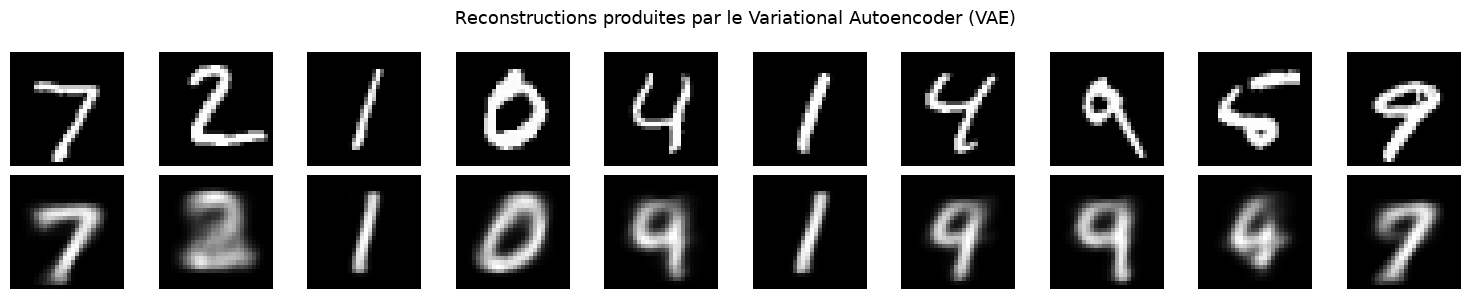

In [5]:
vae.eval()

x_test, _ = next(iter(test_loader))
x_test = x_test[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x_test)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x_test[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("VAE", fontsize=12)

plt.suptitle("Reconstructions produites par le Variational Autoencoder (VAE)", fontsize=13)
plt.tight_layout()
plt.show()


## **6. Visualisation de l'espace latent du VAE**
Nous projetons les moyennes $\mu = (\mu_1, \mu_2)$ de l'ensemble de test.
Contrairement à l'auto-encodeur classique, l'espace latent du VAE est :
- **Centré en $(0, 0)$** avec une variance unitaire grâce au terme $D_{\text{KL}}$.
- **Régulier et continu**, sans discontinuités brutales entre les groupes de chiffres.


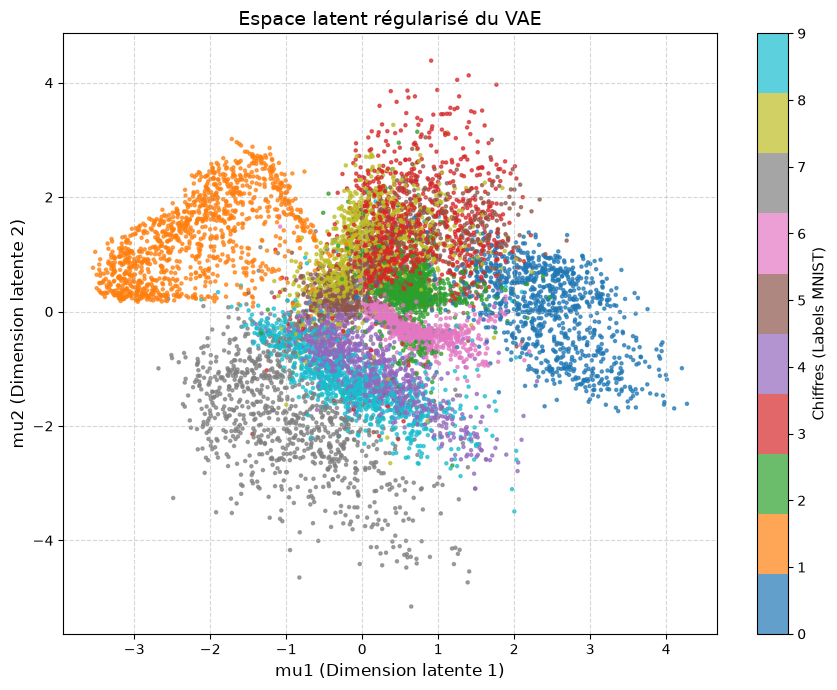

In [6]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=5,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("mu1 (Dimension latente 1)", fontsize=12)
plt.ylabel("mu2 (Dimension latente 2)", fontsize=12)
plt.title("Espace latent régularisé du VAE", fontsize=14)
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label("Chiffres (Labels MNIST)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## **7. Génération de nouvelles images ($z \sim \mathcal{N}(0, I)$)**
C'est la propriété fondamentale d'un modèle génératif : **nous n'avons plus besoin d'image d'entrée**.
Nous échantillonnons directement des vecteurs aléatoires gaussiens dans l'espace latent :
$$z \sim \mathcal{N}(0, I)$$
puis nous les décodons :
$$x_{\text{new}} = \text{Decoder}(z)$$


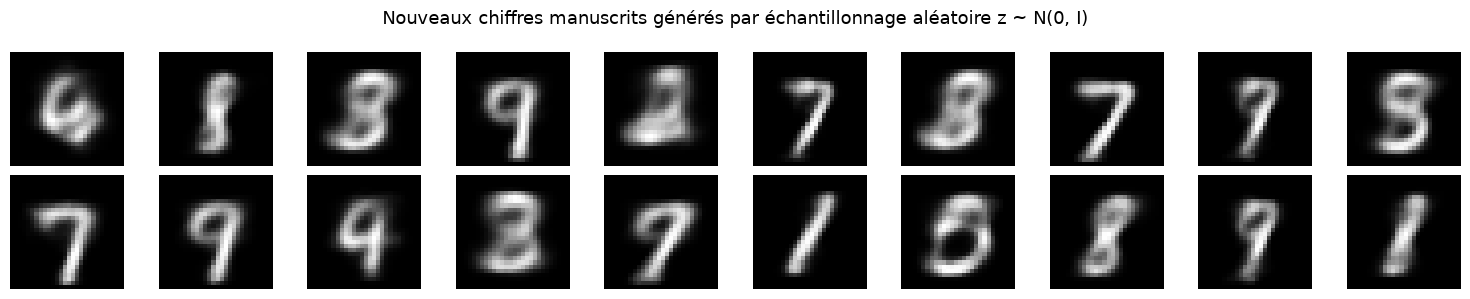

In [7]:
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres manuscrits générés par échantillonnage aléatoire z ~ N(0, I)", fontsize=13)
plt.tight_layout()
plt.show()


## **8. Exploration continue de la variété latente 2D**
Comme notre espace latent est en 2D, nous pouvons parcourir une grille régulière de coordonnées $[-3, 3] \times [-3, 3]$ pour observer comment le décodeur métamorphose continûment un chiffre en un autre le long de la variété.


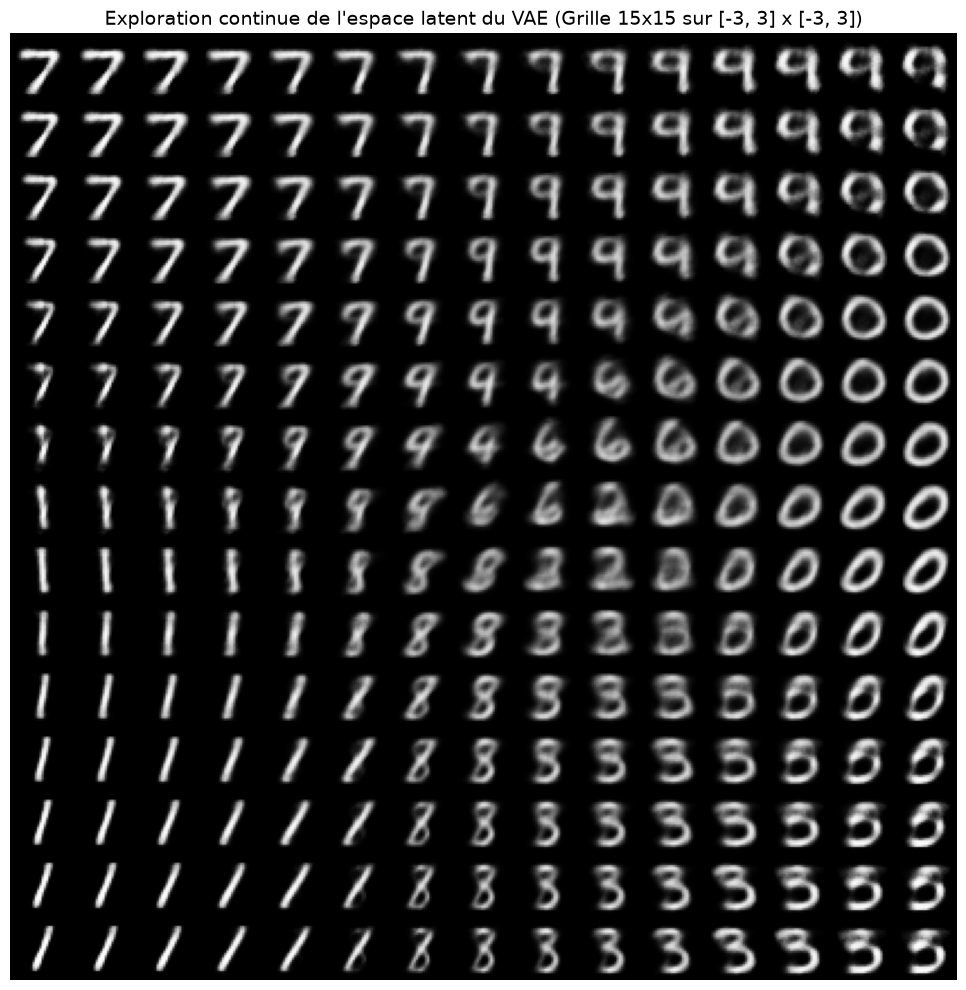

In [8]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            z = torch.tensor(
                [[xi, yi]],
                dtype=torch.float32,
                device=device
            )

            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[
                i*28:(i+1)*28,
                j*28:(j+1)*28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE (Grille 15x15 sur [-3, 3] x [-3, 3])", fontsize=14)
plt.tight_layout()
plt.show()


## **Conclusion générale du TP :**
| Propriété | Modèle Discriminatif | Auto-encodeur Simple (AE) | Variational Autoencoder (VAE) |
| :--- | :--- | :--- | :--- |
| **Objectif** | Prédire la classe $P(y|x)$ | Reconstruire l'entrée $x \to \hat{x}$ | Modéliser la distribution $P(x)$ |
| **Labels requis** | Oui (apprentissage supervisé) | Non (auto-supervisé) | Non (non supervisé probabiliste) |
| **Espace latent** | N/A (couches cachées non régularisées) | Déterministe $z = f(x)$ avec trous | Probabiliste $\mathcal{N}(\mu, \sigma^2) \approx \mathcal{N}(0, I)$ |
| **Génération pure** | Impossible | Incohérente (espace non continu) | Réaliste par échantillonnage $z \sim \mathcal{N}(0, I)$ |
